In [28]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [29]:
df = pd.read_csv('https://raw.githubusercontent.com/arib168/data/main/50_Startups.csv')
df

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


In [30]:
df.shape

(50, 5)

In [31]:
df.isna().sum()

,0
R&D Spend,0
Administration,0
Marketing Spend,0
State,0
Profit,0


In [32]:
df.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')

In [33]:
df.dtypes

,0
R&D Spend,float64
Administration,float64
Marketing Spend,float64
State,object
Profit,float64


In [34]:
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


#Visualisation

<Axes: xlabel='State', ylabel='Profit'>

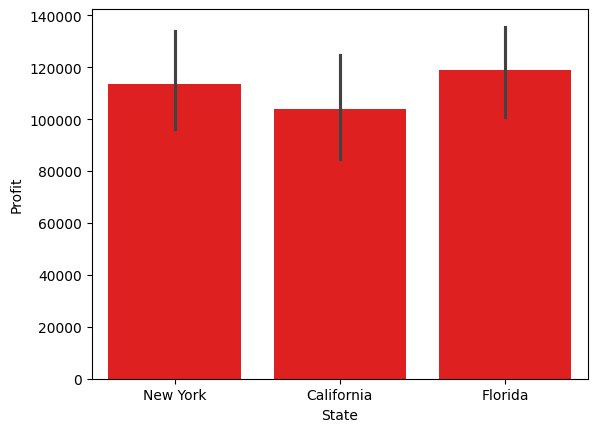

In [35]:
sns.barplot(x=df['State'],y=df['Profit'],color='r')

In [36]:
df.corr(numeric_only=True)

,R&D Spend,Administration,Marketing Spend,Profit
R&D Spend,1.000000,0.241955,0.724248,0.972900
Administration,0.241955,1.000000,-0.032154,0.200717
Marketing Spend,0.724248,-0.032154,1.000000,0.747766
Profit,0.972900,0.200717,0.747766,1.000000


<Axes: >

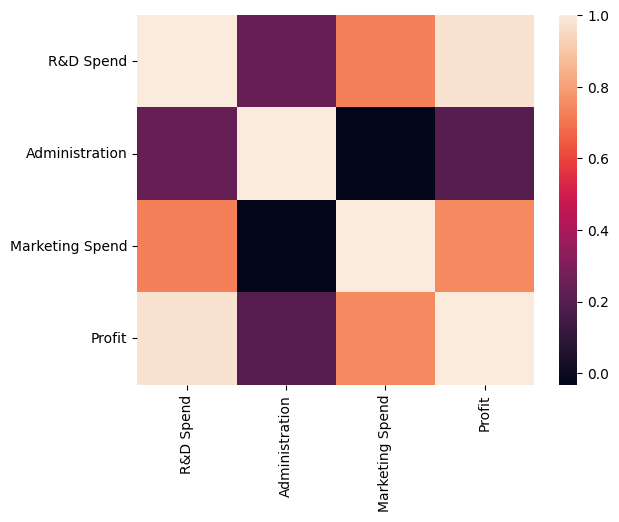

In [37]:
sns.heatmap(df.corr(numeric_only=True))

In [38]:
x =df.iloc[:,:-1]
y = df.iloc[:,-1]

In [39]:
x

,R&D Spend,Administration,Marketing Spend,State
0,165349.20,136897.80,471784.10,New York
1,162597.70,151377.59,443898.53,California
2,153441.51,101145.55,407934.54,Florida
3,144372.41,118671.85,383199.62,New York
4,142107.34,91391.77,366168.42,Florida
5,131876.90,99814.71,362861.36,New York
6,134615.46,147198.87,127716.82,California
7,130298.13,145530.06,323876.68,Florida
8,120542.52,148718.95,311613.29,New York
9,123334.88,108679.17,304981.62,California


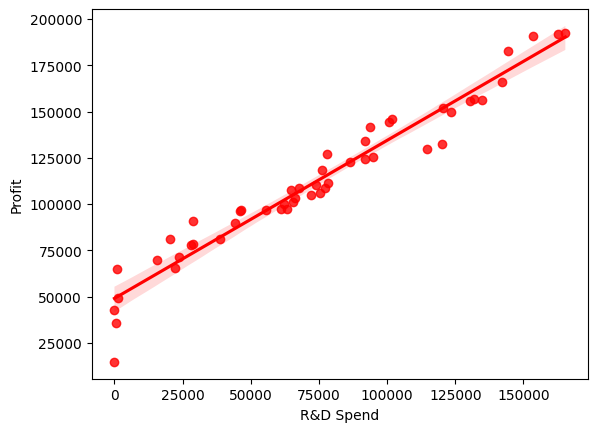

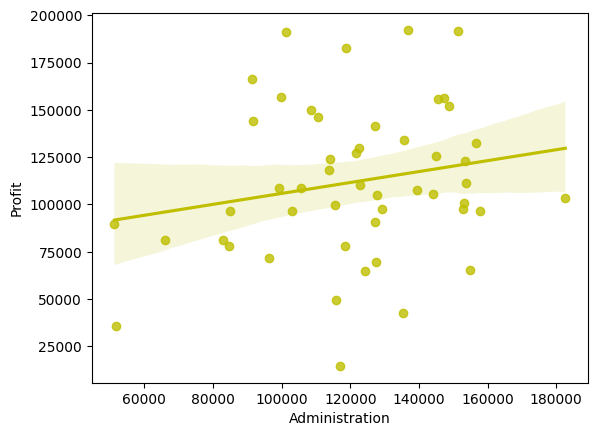

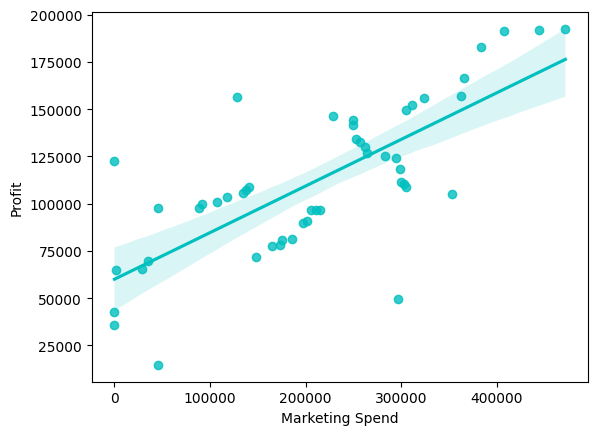

In [40]:
colors =['r','y','c']
for i,c in zip(x.select_dtypes('float64'),colors):
  sns.regplot(data=df,x=i,y='Profit',color=c)
  plt.show()

# ONE HOT ENCODING.
one hot encoding perform after x y seperation

label encoding working (draw back) \
Fruits
---------
Apple   ==>  | 0 \
Mango    ==>  | 2\
Grape     ==> | 1\
Orange   ==>  | 3\
Apple    ==>  | 0\
orange   ==>  | 3\
mango    ==>  | 2

\
this will be affect the model th model gives higer priority to the highest value by encoding.\
so we use one hot encoding to avoid this drawback.



onehot encoding creates each object as coloumns and gives 1 is true else 0


```
Fruits           Apple  mango grape orange
---------
Apple              1     0      0      0  
Mango              0     1      0      0
Grape              0     0      1      0
Orange             0     0      0      1
Apple              1     0      0      0
orange             0     0      0      1
mango              0     1      0      0
```



In [41]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder


In [42]:
data = make_column_transformer((OneHotEncoder(handle_unknown='ignore'),['State']),remainder='passthrough')
col_data = data.fit_transform(x)
col_data

array([[0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.6534920e+05,
        1.3689780e+05, 4.7178410e+05],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 1.6259770e+05,
        1.5137759e+05, 4.4389853e+05],
       [0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.5344151e+05,
        1.0114555e+05, 4.0793454e+05],
       [0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.4437241e+05,
        1.1867185e+05, 3.8319962e+05],
       [0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.4210734e+05,
        9.1391770e+04, 3.6616842e+05],
       [0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.3187690e+05,
        9.9814710e+04, 3.6286136e+05],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 1.3461546e+05,
        1.4719887e+05, 1.2771682e+05],
       [0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.3029813e+05,
        1.4553006e+05, 3.2387668e+05],
       [0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.2054252e+05,
        1.4871895e+05, 3.1161329e+05],
       [1.0000000e+00, 0.0000000e+00,

#Build Model

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
x_train,x_test,y_train,y_test = train_test_split(col_data,y,test_size=.33,random_state=42)

In [45]:
from sklearn.linear_model import LinearRegression

In [46]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [47]:
y_pred = model.predict(x_test)

#Evaluation

In [48]:
from sklearn.metrics import r2_score,mean_absolute_percentage_error,accuracy_score

In [49]:
r2 = r2_score(y_test,y_pred)
mape = mean_absolute_percentage_error(y_test,y_pred)

print(r2,'is r2 score')
print(mape,'is mape')

0.9475312056916008 is r2 score
0.07913259217944185 is mape


In [50]:
df2 = pd.DataFrame({'actual value':y_test,"predict value":y_pred,"difference":y_pred-y_test})

In [51]:
df2

,actual value,predict value,difference
13,134307.35,126187.358759,-8119.991241
39,81005.76,85719.456251,4713.696251
30,99937.59,99648.034933,-289.555067
45,64926.08,45664.955053,-19261.124947
17,125370.37,127106.842490,1736.472490
48,35673.41,51752.874943,16079.464943
26,105733.54,109033.361857,3299.821857
25,107404.34,100575.614106,-6828.725894
32,97427.84,97877.863567,450.023567
19,122776.86,111674.706978,-11102.153022


#slope

In [52]:
model.coef_

array([ 2.70051720e+02,  6.73976207e+02, -9.44027927e+02,  8.04312540e-01,
       -8.99140461e-02,  2.84812890e-02])

#intercept

In [53]:
model.intercept_

np.float64(56913.36123372408)